In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score, brier_score_loss, confusion_matrix, f1_score
import ast


In [23]:
test1_prediction = pd.read_csv('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/test1_prediction.csv')
test2_prediction = pd.read_csv('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/test2_prediction.csv')
test3_prediction = pd.read_csv('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/test3_prediction.csv')
test4_prediction = pd.read_csv('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/test4_prediction.csv')
# test5_prediction = pd.read_csv('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/test5_prediction.csv')

In [24]:
total_prediction = pd.concat([test1_prediction, test2_prediction, test3_prediction, test4_prediction])

In [25]:
y_true = total_prediction['true_label']
y_scores = total_prediction['probability']

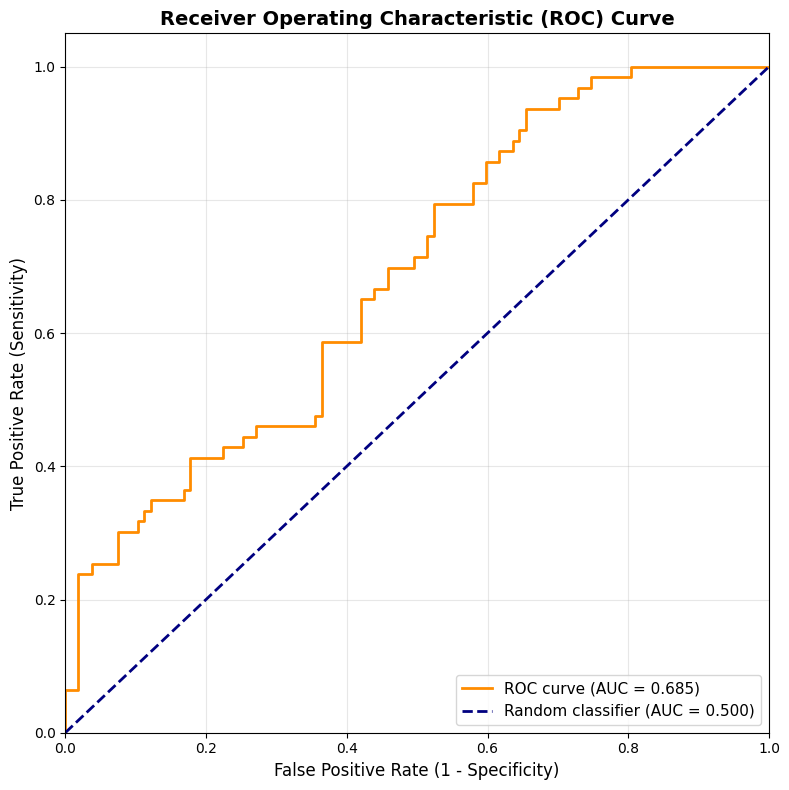


AUC: 0.6852


In [26]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = roc_auc_score(y_true, y_scores)

# Plot ROC curve
plt.figure(figsize=(8, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random classifier (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"\nAUC: {roc_auc:.4f}")


In [27]:
# Load Excel file with subgroup information
excel_data = pd.read_excel('/home/pyq6817/IPMN-Radiomics-Plus-Deeplearning/prediction_probabilities/IPMN_all_cases_final.xlsx')

# Merge prediction data with Excel data based on ID
total_prediction['ID'] = total_prediction['filename']
merged_data = total_prediction.merge(excel_data[['ID', 'Type', 'Risk']], on='ID', how='left')

print(f"Total samples: {len(merged_data)}")
print(f"Samples with subgroup info: {merged_data[['Type', 'Risk']].notna().all(axis=1).sum()}")
print(f"\nSubgroup counts:")
print(f"High Risk: {(merged_data['Risk'] == 'High Risk').sum()}")
print(f"Low Risk: {(merged_data['Risk'] == 'Low Risk').sum()}")
print(f"MD-IPMN: {(merged_data['Type'] == 'MD').sum()}")
print(f"BD-IPMN: {(merged_data['Type'] == 'BD').sum()}")
print(f"High Risk AND MD: {((merged_data['Risk'] == 'High Risk') & (merged_data['Type'] == 'MD')).sum()}")

# Store merged data for later use
data_for_analysis = merged_data.copy()

Total samples: 170
Samples with subgroup info: 170

Subgroup counts:
High Risk: 63
Low Risk: 107
MD-IPMN: 77
BD-IPMN: 93
High Risk AND MD: 44


In [41]:
def calculate_metrics(y_true, y_proba, threshold=None):
    """
    Calculate AUC, sensitivity, specificity, and Brier score.
    If threshold is None, uses optimal threshold based on F-1 score.
    Handles cases where only one class is present (AUC not defined).
    """
    # Check if both classes are present
    unique_classes = np.unique(y_true)
    has_both_classes = len(unique_classes) == 2
    
    # Calculate AUC only if both classes are present
    if has_both_classes:
        try:
            auc = roc_auc_score(y_true, y_proba)
        except ValueError:
            auc = np.nan
    else:
        auc = np.nan  # AUC not defined when only one class present
    
    # Calculate optimal threshold if not provided and both classes are present
    if threshold is None:
        if has_both_classes:
            # Use F-1 score to find optimal threshold
            fpr, tpr, thresholds = roc_curve(y_true, y_proba)
            # Calculate F-1 score for each threshold
            f1_scores = []
            for thresh in thresholds:
                y_pred_thresh = (y_proba >= thresh).astype(int)
                f1 = f1_score(y_true, y_pred_thresh)
                f1_scores.append(f1)
            # Find threshold with maximum F-1 score
            optimal_idx = np.argmax(f1_scores)
            threshold = thresholds[optimal_idx]
        else:
            # If only one class, use 0.5 as default threshold
            threshold = 0.5
    
    # Convert probabilities to binary predictions
    y_pred = (y_proba >= threshold).astype(int)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    # Calculate metrics
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    brier = brier_score_loss(y_true, y_proba)
    
    return {
        'AUC': auc,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Brier Score': brier,
        'Threshold': threshold,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }

# Calculate overall metrics
overall_metrics = calculate_metrics(data_for_analysis['true_label'], data_for_analysis['probability'])

print("="*60)
print("OVERALL METRICS")
print("="*60)
print(f"AUC: {overall_metrics['AUC']:.4f}" if not np.isnan(overall_metrics['AUC']) else "AUC: N/A (only one class present)")
print(f"Sensitivity: {overall_metrics['Sensitivity']:.4f}" if not np.isnan(overall_metrics['Sensitivity']) else "Sensitivity: N/A")
print(f"Specificity: {overall_metrics['Specificity']:.4f}" if not np.isnan(overall_metrics['Specificity']) else "Specificity: N/A")
print(f"Brier Score: {overall_metrics['Brier Score']:.4f}")
print(f"Optimal Threshold: {overall_metrics['Threshold']:.4f}")
print(f"\nConfusion Matrix:")
print(f"  True Positives: {overall_metrics['TP']}")
print(f"  True Negatives: {overall_metrics['TN']}")
print(f"  False Positives: {overall_metrics['FP']}")
print(f"  False Negatives: {overall_metrics['FN']}")

OVERALL METRICS
AUC: 0.6852
Sensitivity: 0.9365
Specificity: 0.3458
Brier Score: 0.2307
Optimal Threshold: 0.3791

Confusion Matrix:
  True Positives: 59
  True Negatives: 37
  False Positives: 70
  False Negatives: 4



ANALYSIS 1: BY TYPE (MD vs BD)

OVERALL METRICS (Type-based analysis)
AUC: 0.6852
Sensitivity: 0.9365
Specificity: 0.3458
Brier Score: 0.2307
Optimal Threshold: 0.3791

TYPE SUBGROUP METRICS

MD (n=77):
  AUC: 0.5937
  Sensitivity: 0.9318
  Specificity: 0.1515
  Brier Score: 0.2451
  Confusion Matrix: TP=41, TN=5, FP=28, FN=3

BD (n=93):
  AUC: 0.6942
  Sensitivity: 0.9474
  Specificity: 0.4324
  Brier Score: 0.2188
  Confusion Matrix: TP=18, TN=32, FP=42, FN=1


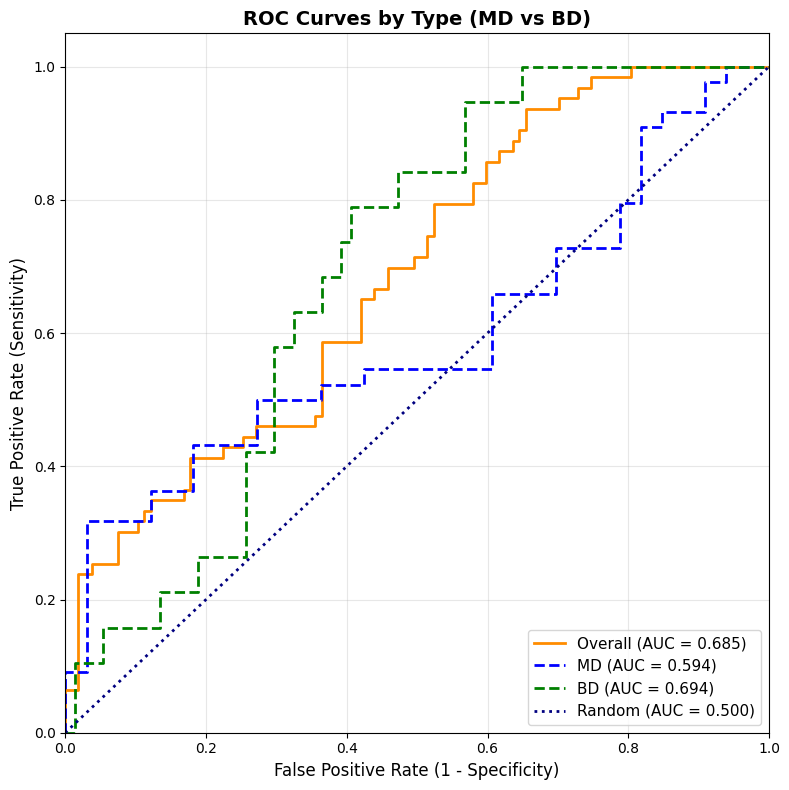

In [42]:
# ============================================================================
# ANALYSIS 1: By Type (MD vs BD)
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 1: BY TYPE (MD vs BD)")
print("="*80)

# Filter data with valid Type information
type_data = data_for_analysis[data_for_analysis['Type'].notna()].copy()

# Calculate overall metrics for Type-based analysis
type_overall_metrics = calculate_metrics(type_data['true_label'], type_data['probability'])
print("\n" + "="*60)
print("OVERALL METRICS (Type-based analysis)")
print("="*60)
print(f"AUC: {type_overall_metrics['AUC']:.4f}" if not np.isnan(type_overall_metrics['AUC']) else "AUC: N/A")
print(f"Sensitivity: {type_overall_metrics['Sensitivity']:.4f}" if not np.isnan(type_overall_metrics['Sensitivity']) else "Sensitivity: N/A")
print(f"Specificity: {type_overall_metrics['Specificity']:.4f}" if not np.isnan(type_overall_metrics['Specificity']) else "Specificity: N/A")
print(f"Brier Score: {type_overall_metrics['Brier Score']:.4f}")
print(f"Optimal Threshold: {type_overall_metrics['Threshold']:.4f}")

# Calculate metrics for MD and BD subgroups
type_results = {}

# MD subgroup
md_mask = type_data['Type'] == 'MD'
if md_mask.sum() > 0:
    md_data = type_data[md_mask]
    type_results['MD'] = calculate_metrics(
        md_data['true_label'], 
        md_data['probability'],
        threshold=type_overall_metrics['Threshold']
    )

# BD subgroup
bd_mask = type_data['Type'] == 'BD'
if bd_mask.sum() > 0:
    bd_data = type_data[bd_mask]
    type_results['BD'] = calculate_metrics(
        bd_data['true_label'], 
        bd_data['probability'],
        threshold=type_overall_metrics['Threshold']
    )

# Print results for Type subgroups
print("\n" + "="*60)
print("TYPE SUBGROUP METRICS")
print("="*60)

for subgroup_name, metrics in type_results.items():
    n_samples = md_mask.sum() if subgroup_name == 'MD' else bd_mask.sum()
    
    print(f"\n{subgroup_name} (n={n_samples}):")
    # AUC
    if not np.isnan(metrics['AUC']):
        print(f"  AUC: {metrics['AUC']:.4f}")
    else:
        print(f"  AUC: N/A (only one class present)")
    
    # Sensitivity
    if not np.isnan(metrics['Sensitivity']):
        print(f"  Sensitivity: {metrics['Sensitivity']:.4f}")
    else:
        print(f"  Sensitivity: N/A (TP+FN=0, no positive cases in true labels)")
    
    # Specificity
    if not np.isnan(metrics['Specificity']):
        print(f"  Specificity: {metrics['Specificity']:.4f}")
    else:
        print(f"  Specificity: N/A (TN+FP=0, no negative cases in true labels)")
    
    print(f"  Brier Score: {metrics['Brier Score']:.4f}")
    print(f"  Confusion Matrix: TP={metrics['TP']}, TN={metrics['TN']}, FP={metrics['FP']}, FN={metrics['FN']}")

# Plot ROC curves for Type analysis
fig, ax = plt.subplots(figsize=(8, 8))

# Overall ROC curve
fpr_overall, tpr_overall, _ = roc_curve(type_data['true_label'], type_data['probability'])
roc_auc_overall = type_overall_metrics['AUC']
ax.plot(fpr_overall, tpr_overall, color='darkorange', lw=2, 
        label=f'Overall (AUC = {roc_auc_overall:.3f})')

# MD ROC curve
if 'MD' in type_results and not np.isnan(type_results['MD']['AUC']):
    md_data = type_data[type_data['Type'] == 'MD']
    fpr_md, tpr_md, _ = roc_curve(md_data['true_label'], md_data['probability'])
    auc_md = type_results['MD']['AUC']
    ax.plot(fpr_md, tpr_md, color='blue', lw=2, linestyle='--', 
            label=f'MD (AUC = {auc_md:.3f})')

# BD ROC curve
if 'BD' in type_results and not np.isnan(type_results['BD']['AUC']):
    bd_data = type_data[type_data['Type'] == 'BD']
    fpr_bd, tpr_bd, _ = roc_curve(bd_data['true_label'], bd_data['probability'])
    auc_bd = type_results['BD']['AUC']
    ax.plot(fpr_bd, tpr_bd, color='green', lw=2, linestyle='--', 
            label=f'BD (AUC = {auc_bd:.3f})')

# Random classifier line
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':', label='Random (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curves by Type (MD vs BD)', fontsize=14, fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


ANALYSIS 2: BY RISK (Low Risk vs High Risk)

OVERALL METRICS (Risk-based analysis)
AUC: 0.6852
Sensitivity: 0.9365
Specificity: 0.3458
Brier Score: 0.2307
Optimal Threshold: 0.3791

RISK SUBGROUP METRICS

Low Risk (n=107):
  AUC: N/A (only one class present)
  Sensitivity: N/A (TP+FN=0, no positive cases in true labels)
  Specificity: 0.3458
  Brier Score: 0.2564
  Confusion Matrix: TP=0, TN=37, FP=70, FN=0

High Risk (n=63):
  AUC: N/A (only one class present)
  Sensitivity: 0.9365
  Specificity: N/A (TN+FP=0, no negative cases in true labels)
  Brier Score: 0.1870
  Confusion Matrix: TP=59, TN=0, FP=0, FN=4


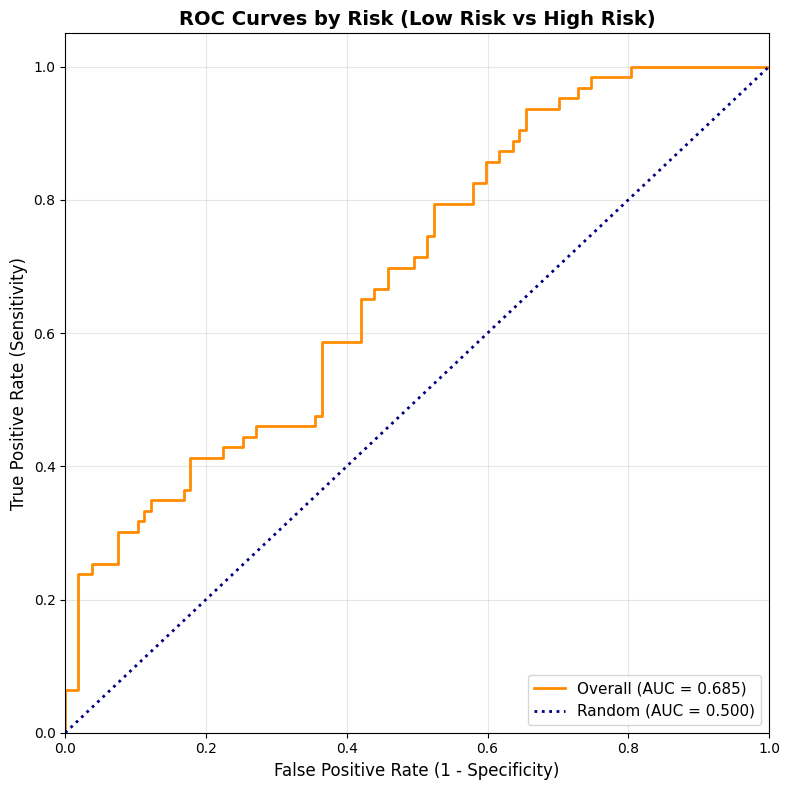

In [45]:
# ============================================================================
# ANALYSIS 2: By Risk (Low Risk vs High Risk)
# ============================================================================
print("\n" + "="*80)
print("ANALYSIS 2: BY RISK (Low Risk vs High Risk)")
print("="*80)

# Filter data with valid Risk information
risk_data = data_for_analysis[data_for_analysis['Risk'].notna()].copy()

# Calculate overall metrics for Risk-based analysis
risk_overall_metrics = calculate_metrics(risk_data['true_label'], risk_data['probability'])
print("\n" + "="*60)
print("OVERALL METRICS (Risk-based analysis)")
print("="*60)
print(f"AUC: {risk_overall_metrics['AUC']:.4f}" if not np.isnan(risk_overall_metrics['AUC']) else "AUC: N/A")
print(f"Sensitivity: {risk_overall_metrics['Sensitivity']:.4f}" if not np.isnan(risk_overall_metrics['Sensitivity']) else "Sensitivity: N/A")
print(f"Specificity: {risk_overall_metrics['Specificity']:.4f}" if not np.isnan(risk_overall_metrics['Specificity']) else "Specificity: N/A")
print(f"Brier Score: {risk_overall_metrics['Brier Score']:.4f}")
print(f"Optimal Threshold: {risk_overall_metrics['Threshold']:.4f}")

# Calculate metrics for Low Risk and High Risk subgroups
risk_results = {}

# Low Risk subgroup
low_risk_mask = risk_data['Risk'] == 'Low Risk'
if low_risk_mask.sum() > 0:
    low_risk_data = risk_data[low_risk_mask]
    risk_results['Low Risk'] = calculate_metrics(
        low_risk_data['true_label'], 
        low_risk_data['probability'],
        threshold=risk_overall_metrics['Threshold']
    )

# High Risk subgroup
high_risk_mask = risk_data['Risk'] == 'High Risk'
if high_risk_mask.sum() > 0:
    high_risk_data = risk_data[high_risk_mask]
    risk_results['High Risk'] = calculate_metrics(
        high_risk_data['true_label'], 
        high_risk_data['probability'],
        threshold=risk_overall_metrics['Threshold']
    )

# Print results for Risk subgroups
print("\n" + "="*60)
print("RISK SUBGROUP METRICS")
print("="*60)

for subgroup_name, metrics in risk_results.items():
    n_samples = low_risk_mask.sum() if subgroup_name == 'Low Risk' else high_risk_mask.sum()
    
    print(f"\n{subgroup_name} (n={n_samples}):")
    # AUC
    if not np.isnan(metrics['AUC']):
        print(f"  AUC: {metrics['AUC']:.4f}")
    else:
        print(f"  AUC: N/A (only one class present)")
    
    # Sensitivity
    if not np.isnan(metrics['Sensitivity']):
        print(f"  Sensitivity: {metrics['Sensitivity']:.4f}")
    else:
        print(f"  Sensitivity: N/A (TP+FN=0, no positive cases in true labels)")
    
    # Specificity
    if not np.isnan(metrics['Specificity']):
        print(f"  Specificity: {metrics['Specificity']:.4f}")
    else:
        print(f"  Specificity: N/A (TN+FP=0, no negative cases in true labels)")
    
    print(f"  Brier Score: {metrics['Brier Score']:.4f}")
    print(f"  Confusion Matrix: TP={metrics['TP']}, TN={metrics['TN']}, FP={metrics['FP']}, FN={metrics['FN']}")

# Plot ROC curves for Risk analysis
fig, ax = plt.subplots(figsize=(8, 8))

# Overall ROC curve
fpr_overall, tpr_overall, _ = roc_curve(risk_data['true_label'], risk_data['probability'])
roc_auc_overall = risk_overall_metrics['AUC']
ax.plot(fpr_overall, tpr_overall, color='darkorange', lw=2, 
        label=f'Overall (AUC = {roc_auc_overall:.3f})')

# Low Risk ROC curve
if 'Low Risk' in risk_results and not np.isnan(risk_results['Low Risk']['AUC']):
    low_risk_data = risk_data[risk_data['Risk'] == 'Low Risk']
    fpr_low, tpr_low, _ = roc_curve(low_risk_data['true_label'], low_risk_data['probability'])
    auc_low = risk_results['Low Risk']['AUC']
    ax.plot(fpr_low, tpr_low, color='blue', lw=2, linestyle='--', 
            label=f'Low Risk (AUC = {auc_low:.3f})')

# High Risk ROC curve
if 'High Risk' in risk_results and not np.isnan(risk_results['High Risk']['AUC']):
    high_risk_data = risk_data[risk_data['Risk'] == 'High Risk']
    fpr_high, tpr_high, _ = roc_curve(high_risk_data['true_label'], high_risk_data['probability'])
    auc_high = risk_results['High Risk']['AUC']
    ax.plot(fpr_high, tpr_high, color='green', lw=2, linestyle='--', 
            label=f'High Risk (AUC = {auc_high:.3f})')

# Random classifier line
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle=':', label='Random (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curves by Risk (Low Risk vs High Risk)', fontsize=14, fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
# ============================================================================
# CREATE SUMMARY TABLES
# ============================================================================

# Summary table for Type analysis
print("\n" + "="*80)
print("SUMMARY TABLE 1: BY TYPE (MD vs BD)")
print("="*80)

type_summary_data = {
    'Metric': ['AUC', 'Sensitivity', 'Specificity', 'Brier Score'],
    'Overall': [
        type_overall_metrics['AUC'],
        type_overall_metrics['Sensitivity'],
        type_overall_metrics['Specificity'],
        type_overall_metrics['Brier Score']
    ]
}

for subgroup_name in ['MD', 'BD']:
    if subgroup_name in type_results:
        metrics = type_results[subgroup_name]
        type_summary_data[subgroup_name] = [
            metrics['AUC'],
            metrics['Sensitivity'],
            metrics['Specificity'],
            metrics['Brier Score']
        ]
    else:
        type_summary_data[subgroup_name] = [np.nan, np.nan, np.nan, np.nan]

type_summary_df = pd.DataFrame(type_summary_data)
type_summary_df_display = type_summary_df.copy()
type_summary_df_display = type_summary_df_display.fillna('N/A')
print(type_summary_df_display.to_string(index=False))
type_summary_df_display.to_csv('metrics_summary_by_type.csv', index=False)
print("\nType summary saved to 'metrics_summary_by_type.csv'")

# Summary table for Risk analysis
print("\n" + "="*80)
print("SUMMARY TABLE 2: BY RISK (Low Risk vs High Risk)")
print("="*80)

risk_summary_data = {
    'Metric': ['AUC', 'Sensitivity', 'Specificity', 'Brier Score'],
    'Overall': [
        risk_overall_metrics['AUC'],
        risk_overall_metrics['Sensitivity'],
        risk_overall_metrics['Specificity'],
        risk_overall_metrics['Brier Score']
    ]
}

for subgroup_name in ['Low Risk', 'High Risk']:
    if subgroup_name in risk_results:
        metrics = risk_results[subgroup_name]
        risk_summary_data[subgroup_name] = [
            metrics['AUC'],
            metrics['Sensitivity'],
            metrics['Specificity'],
            metrics['Brier Score']
        ]
    else:
        risk_summary_data[subgroup_name] = [np.nan, np.nan, np.nan, np.nan]

risk_summary_df = pd.DataFrame(risk_summary_data)
risk_summary_df_display = risk_summary_df.copy()
risk_summary_df_display = risk_summary_df_display.fillna('N/A')
print(risk_summary_df_display.to_string(index=False))
risk_summary_df_display.to_csv('metrics_summary_by_risk.csv', index=False)
print("\nRisk summary saved to 'metrics_summary_by_risk.csv'")


SUMMARY TABLE 1: BY TYPE (MD vs BD)
     Metric  Overall       MD       BD
        AUC 0.685210 0.593664 0.694168
Sensitivity 0.936508 0.931818 0.947368
Specificity 0.345794 0.151515 0.432432
Brier Score 0.230713 0.245148 0.218761

Type summary saved to 'metrics_summary_by_type.csv'

SUMMARY TABLE 2: BY RISK (Low Risk vs High Risk)
     Metric  Overall  Low Risk High Risk
        AUC 0.685210       N/A       N/A
Sensitivity 0.936508       N/A  0.936508
Specificity 0.345794  0.345794       N/A
Brier Score 0.230713  0.256436  0.187025

Risk summary saved to 'metrics_summary_by_risk.csv'
